In [1]:
%pip install boto3 pandas==2.2.3 numpy==1.26.4 scikit-learn jupyter matplotlib "sagemaker<3" scipy==1.14.1

  Using cached jupyter-1.1.1-py2.py3-none-any.whl (2.7 kB)
  Using cached sagemaker-2.257.7-py3-none-any.whl (1.7 MB)
  Using cached notebook-7.6.5-py3-none-any.whl (5.6 MB)
  Using cached jupyterlab-4.6.6-py3-none-any.whl (17.3 MB)
  Using cached nbconvert-7.17.2-py3-none-any.whl (262 kB)
  Using cached ipywidgets-8.1.9-py3-none-any.whl (140 kB)
  Using cached jupyter_console-6.6.3-py3-none-any.whl (24 kB)
  Using cached packaging-24.2-py3-none-any.whl (65 kB)
  Using cached pathos-0.3.5-py3-none-any.whl (82 kB)
     ---------------------------------------- 1.7/1.7 MB 1.1 MB/s eta 0:00:00
     ---------------------------------------- 1.7/1.7 MB 1.0 MB/s eta 0:00:00
     ---------------------------------------- 1.7/1.7 MB 1.1 MB/s eta 0:00:00
     ---------------------------------------- 1.7/1.7 MB 1.2 MB/s eta 0:00:00
     ---------------------------------------- 1.7/1.7 MB 1.1 MB/s eta 0:00:00
     ---------------------------------------- 1.7/1.7 MB 1.1 MB/s eta 0:00:00
     --------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress t

In [21]:
from pathlib import Path
import io, json, time
import numpy as np
import pandas as pd
import scipy.sparse as sp
import boto3

BUCKET   = "recingmovies708759"
ROLE_ARN = "arn:aws:iam::903797724117:role/service-role/AmazonSageMaker-ExecutionRole-20260921T093009"

CANDIDATES = [
    Path("../data/ml-100k"),
    Path(r"C:\Users\jimen\OneDrive\Escritorio\Integración de servicios de aprendizaje automático\ProyectoISSA708759\data\ml-100k"),
]
DATA_DIR = next((p for p in CANDIDATES if p.exists()), None)
assert DATA_DIR is not None, "No encontré la carpeta ml-100k"
PROCESSED_DIR = DATA_DIR.parent / "processed"
PROCESSED_DIR.mkdir(exist_ok=True)

REGION = boto3.Session().region_name
print("Datos:", DATA_DIR.resolve())
print("Región:", REGION)

Datos: C:\Users\jimen\OneDrive\Escritorio\Integración de servicios de aprendizaje automático\ProyectoISSA708759\data\ml-100k
Región: us-east-1


In [3]:
ratings = pd.read_csv(DATA_DIR / "u.data", sep="\t",
                      names=["user_id", "movie_id", "rating", "timestamp"])
movies = pd.read_csv(DATA_DIR / "u.item", sep="|", encoding="latin-1", header=None,
                     usecols=[0, 1, 2], names=["movie_id", "title", "release_date"])
users = pd.read_csv(DATA_DIR / "u.user", sep="|",
                    names=["user_id", "age", "gender", "occupation", "zip"])

N_USERS  = ratings.user_id.max()    # 943
N_MOVIES = ratings.movie_id.max()   # 1682
FEATURE_DIM = N_USERS + N_MOVIES    # 2625

print("Calificaciones:", ratings.shape, "| Películas:", movies.shape, "| Usuarios:", users.shape)
print("Usuarios:", N_USERS, "| Películas:", N_MOVIES, "| feature_dim:", FEATURE_DIM)
print("Sparsity: {:.2%}".format(1 - len(ratings) / (N_USERS * N_MOVIES)))
ratings.head()

Calificaciones: (100000, 4) | Películas: (1682, 3) | Usuarios: (943, 5)
Usuarios: 943 | Películas: 1682 | feature_dim: 2625
Sparsity: 93.70%


,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


Distribución de calificaciones:
rating
1     6110
2    11370
3    27145
4    34174
5    21201
Name: count, dtype: int64

Calificaciones por usuario:
count    943.000000
mean     106.044539
std      100.931743
min       20.000000
25%       33.000000
50%       65.000000
75%      148.000000
max      737.000000
dtype: float64

Calificaciones por película:
count    1682.000000
mean       59.453032
std        80.383846
min         1.000000
25%         6.000000
50%        27.000000
75%        80.000000
max       583.000000
dtype: float64


<Axes: title={'center': 'Distribución de calificaciones'}, xlabel='rating'>

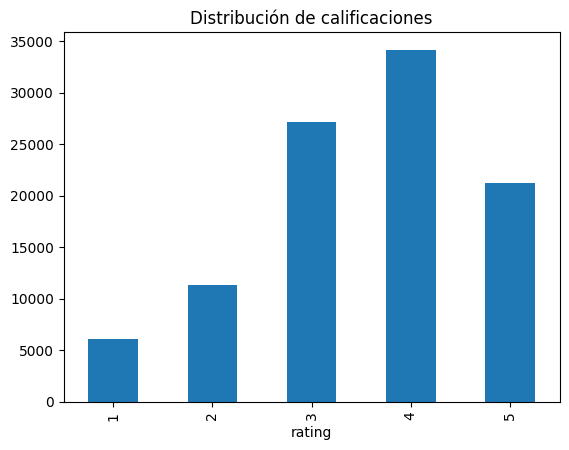

In [4]:
print("Distribución de calificaciones:")
print(ratings["rating"].value_counts().sort_index())
print("\nCalificaciones por usuario:")
print(ratings.groupby("user_id").size().describe())
print("\nCalificaciones por película:")
print(ratings.groupby("movie_id").size().describe())

ratings["rating"].value_counts().sort_index().plot(kind="bar", title="Distribución de calificaciones")

In [5]:
train = ratings.sample(frac=0.8, random_state=42)
test  = ratings.drop(train.index)

train.to_csv(PROCESSED_DIR / "train.csv", index=False)
test.to_csv(PROCESSED_DIR / "test.csv", index=False)
print("Train:", train.shape, "| Test:", test.shape)

Train: (80000, 4) | Test: (20000, 4)


In [6]:
def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)))

def mae(y_true, y_pred):
    return float(np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred))))

global_mean = train.rating.mean()
print("RMSE (promedio global): {:.4f}".format(rmse(test.rating, np.full(len(test), global_mean))))

RMSE (promedio global): 1.1303


In [7]:
def train_mf(df, n_users, n_items, k=20, epochs=25, lr=0.005, reg=0.02, seed=42, eval_df=None):
    rng = np.random.default_rng(seed)
    mu = df.rating.mean()
    bu, bi = np.zeros(n_users), np.zeros(n_items)
    P = rng.normal(0, 0.1, (n_users, k))
    Q = rng.normal(0, 0.1, (n_items, k))
    u = df.user_id.values - 1
    i = df.movie_id.values - 1
    r = df.rating.values.astype(float)

    def predict(uu, ii):
        return np.clip(mu + bu[uu] + bi[ii] + (P[uu] * Q[ii]).sum(axis=1), 1, 5)

    for epoch in range(1, epochs + 1):
        for j in rng.permutation(len(r)):
            a, b = u[j], i[j]
            e = r[j] - (mu + bu[a] + bi[b] + P[a] @ Q[b])
            bu[a] += lr * (e - reg * bu[a])
            bi[b] += lr * (e - reg * bi[b])
            pa = P[a].copy()
            P[a] += lr * (e * Q[b] - reg * P[a])
            Q[b] += lr * (e * pa - reg * Q[b])
        if eval_df is not None and epoch % 5 == 0:
            p = predict(eval_df.user_id.values - 1, eval_df.movie_id.values - 1)
            print("Época {:2d} | RMSE test: {:.4f}".format(epoch, rmse(eval_df.rating, p)))
    return predict

predict_local = train_mf(train, N_USERS, N_MOVIES, eval_df=test)
p_local = predict_local(test.user_id.values - 1, test.movie_id.values - 1)
BASELINE_RMSE, BASELINE_MAE = rmse(test.rating, p_local), mae(test.rating, p_local)
print("\nBASELINE -> RMSE: {:.4f} | MAE: {:.4f}".format(BASELINE_RMSE, BASELINE_MAE))

Época  5 | RMSE test: 0.9560
Época 10 | RMSE test: 0.9448
Época 15 | RMSE test: 0.9399
Época 20 | RMSE test: 0.9348
Época 25 | RMSE test: 0.9307

BASELINE -> RMSE: 0.9307 | MAE: 0.7322


In [8]:
s3 = boto3.client("s3")
s3.upload_file(str(PROCESSED_DIR / "train.csv"), BUCKET, "processed/train.csv")
s3.upload_file(str(PROCESSED_DIR / "test.csv"),  BUCKET, "processed/test.csv")
s3.upload_file(str(DATA_DIR / "u.item"),         BUCKET, "raw/u.item")
s3.upload_file(str(DATA_DIR / "u.data"),         BUCKET, "raw/u.data")

for obj in s3.list_objects_v2(Bucket=BUCKET).get("Contents", []):
    print(obj["Key"], obj["Size"])

fm/test/test.protobuf 1280000
fm/train/train.protobuf 5120000
processed/test.csv 415682
processed/train.csv 1663561
raw/u.data 1979173
raw/u.item 236344


In [9]:
%pip install "sagemaker<3" matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
%pip install --force-reinstall --no-cache-dir packaging

     ------------------------------------ 130.0/130.0 kB 696.0 kB/s eta 0:00:00
  Attempting uninstall: packaging
    Found existing installation: packaging 24.2
    Uninstalling packaging-24.2:
      Successfully uninstalled packaging-24.2
Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sagemaker 2.253.1 requires packaging<25,>=23.0, but you have packaging 26.3 which is incompatible.

[notice] A new release of pip available: 22.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
%pip install sagemaker

  Using cached packaging-24.2-py3-none-any.whl (65 kB)
  Attempting uninstall: packaging
    Found existing installation: packaging 26.3
    Uninstalling packaging-26.3:
      Successfully uninstalled packaging-26.3
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
import sagemaker
from sagemaker.amazon.common import write_spmatrix_to_sparse_tensor

def to_sparse(df):
    n = len(df)
    rows = np.repeat(np.arange(n), 2)
    cols = np.column_stack([df.user_id.values - 1,
                            N_USERS + df.movie_id.values - 1]).ravel()
    X = sp.csr_matrix((np.ones(2 * n, dtype="float32"), (rows, cols)),
                      shape=(n, FEATURE_DIM))
    y = df.rating.values.astype("float32")
    return X, y

def upload_recordio(X, y, key):
    buf = io.BytesIO()
    write_spmatrix_to_sparse_tensor(buf, X, y)
    buf.seek(0)
    s3.upload_fileobj(buf, BUCKET, key)
    print("Subido a s3://{}/{}".format(BUCKET, key))

X_train, y_train = to_sparse(train)
X_test,  y_test  = to_sparse(test)
upload_recordio(X_train, y_train, "fm/train/train.protobuf")
upload_recordio(X_test,  y_test,  "fm/test/test.protobuf")

sagemaker.config INFO - Not applying SDK defaults from location: C:\ProgramData\sagemaker\sagemaker\config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: C:\Users\jimen\AppData\Local\sagemaker\sagemaker\config.yaml
Subido a s3://recingmovies708759/fm/train/train.protobuf
Subido a s3://recingmovies708759/fm/test/test.protobuf


In [20]:
import boto3
import json

iam = boto3.client("iam")

POLICY_ARN = (
    "arn:aws:iam::903797724117:"
    "policy/service-role/AmazonSageMaker-ExecutionPolicy-20260921T093009"
)

# Obtener versión predeterminada
policy = iam.get_policy(PolicyArn=POLICY_ARN)["Policy"]
version_id = policy["DefaultVersionId"]

# Obtener documento de permisos
policy_version = iam.get_policy_version(
    PolicyArn=POLICY_ARN,
    VersionId=version_id
)

print(json.dumps(
    policy_version["PolicyVersion"]["Document"],
    indent=2
))

{
  "Version": "2012-10-17",
  "Statement": [
    {
      "Effect": "Allow",
      "Action": [
        "s3:GetObject",
        "s3:PutObject",
        "s3:DeleteObject",
        "s3:ListBucket"
      ],
      "Resource": [
        "arn:aws:s3:::*"
      ]
    }
  ]
}


In [22]:
import sagemaker
from sagemaker import image_uris
from sagemaker.estimator import Estimator
from sagemaker.inputs import TrainingInput

sm_session = sagemaker.Session(default_bucket=BUCKET)
container = image_uris.retrieve("factorization-machines", REGION)

fm = Estimator(
    image_uri=container,
    role=ROLE_ARN,
    instance_count=1,
    instance_type="ml.m5.large",
    output_path="s3://{}/fm/output".format(BUCKET),
    sagemaker_session=sm_session,
)
fm.set_hyperparameters(
    feature_dim=FEATURE_DIM,
    predictor_type="regressor",
    num_factors=64,
    epochs=30,
    mini_batch_size=1000,
)

fm.fit({
    "train": TrainingInput("s3://{}/fm/train/".format(BUCKET), content_type="application/x-recordio-protobuf"),
    "test":  TrainingInput("s3://{}/fm/test/".format(BUCKET),  content_type="application/x-recordio-protobuf"),
})
print("Artefacto del modelo:", fm.model_data)

INFO:sagemaker.image_uris:Same images used for training and inference. Defaulting to image scope: inference.
INFO:sagemaker.image_uris:Ignoring unnecessary instance type: None.
INFO:sagemaker.telemetry.telemetry_logging:SageMaker Python SDK will collect telemetry to help us better understand our user's needs, diagnose issues, and deliver additional features.
To opt out of telemetry, please disable via TelemetryOptOut parameter in SDK defaults config. For more information, refer to https://sagemaker.readthedocs.io/en/stable/overview.html#configuring-and-using-defaults-with-the-sagemaker-python-sdk.
INFO:sagemaker:Creating training-job with name: factorization-machines-2026-11-23-10-44-38-355


2026-11-23 10:44:39 Starting - Starting the training job...
2026-11-23 10:44:59 Starting - Preparing the instances for training...
2026-11-23 10:45:26 Downloading - Downloading input data...
2026-11-23 10:46:06 Downloading - Downloading the training image...........Docker entrypoint called with argument(s): train
Running default environment configuration script
/opt/amazon/lib/python3.8/site-packages/mxnet/model.py:97: SyntaxWarning: "is" with a literal. Did you mean "=="?
  if num_device is 1 and 'dist' not in kvstore:
[11/23/2026 10:48:08 INFO 140069562423104] Reading default configuration from /opt/amazon/lib/python3.8/site-packages/algorithm/resources/default-conf.json: {'epochs': 1, 'mini_batch_size': '1000', 'use_bias': 'true', 'use_linear': 'true', 'bias_lr': '0.1', 'linear_lr': '0.001', 'factors_lr': '0.0001', 'bias_wd': '0.01', 'linear_wd': '0.001', 'factors_wd': '0.00001', 'bias_init_method': 'normal', 'bias_init_sigma': '0.01', 'linear_init_method': 'normal', 'linear_init_si

In [23]:
ENDPOINT_NAME = "recing-fm-endpoint"

predictor = fm.deploy(
    initial_instance_count=1,
    instance_type="ml.m5.large",
    endpoint_name=ENDPOINT_NAME,
)
print("Endpoint listo:", ENDPOINT_NAME)

INFO:sagemaker:Creating model with name: factorization-machines-2026-11-23-10-49-46-843
INFO:sagemaker:Creating endpoint-config with name recing-fm-endpoint
INFO:sagemaker:Creating endpoint with name recing-fm-endpoint


-------!Endpoint listo: recing-fm-endpoint


In [24]:
runtime = boto3.client("sagemaker-runtime")

def predict_pairs(pairs, batch_size=500):
    """pairs: lista de (user_id, movie_id). Devuelve calificaciones predichas (1 a 5)."""
    scores = []
    for s in range(0, len(pairs), batch_size):
        chunk = pairs[s:s + batch_size]
        instances = [
            {"data": {"features": {"keys": [int(u) - 1, N_USERS + int(m) - 1],
                                   "values": [1, 1],
                                   "shape": [FEATURE_DIM]}}}
            for u, m in chunk
        ]
        resp = runtime.invoke_endpoint(
            EndpointName=ENDPOINT_NAME,
            ContentType="application/json",
            Body=json.dumps({"instances": instances}),
        )
        out = json.loads(resp["Body"].read())
        scores.extend(p["score"] for p in out["predictions"])
    return np.clip(np.array(scores), 1, 5)

print(predict_pairs([(1, 1), (1, 50), (2, 100)]))

╭─────────────────────────────── Traceback (most recent call last) ────────────────────────────────╮
│ in <module>:23                                                                                   │
│                                                                                                  │
│   20 │   │   scores.extend(p["score"] for p in out["predictions"])                               │
│   21 │   return np.clip(np.array(scores), 1, 5)                                                  │
│   22                                                                                             │
│ ❱ 23 print(predict_pairs([(1, 1), (1, 50), (2, 100)]))                                           │
│   24                                                                                             │
│                                                                                                  │
│ in predict_pairs:17                                                                              │
│                                                                                                  │
│   14 │   │   resp = runtime.invoke_endpoint(                                                     │
│   15 │   │   │   EndpointName=ENDPOINT_NAME,                                                     │
│   16 │   │   │   ContentType="application/json",                                                 │
│ ❱ 17 │   │   │   Body=json.dumps({"instances": instances}),                                      │
│   18 │   │   )                                                                                   │
│   19 │   │   out = json.loads(resp["Body"].read())                                               │
│   20 │   │   scores.extend(p["score"] for p in out["predictions"])                               │
│                                                                                                  │
│ c:\Users\jimen\.pyenv\pyenv-win\versions\3.10.8\lib\json\__init__.py:231 in dumps                │
│                                                                                                  │
│   228 │   │   check_circular and allow_nan and                                                   │
│   229 │   │   cls is None and indent is None and separators is None and                          │
│   230 │   │   default is None and not sort_keys and not kw):                                     │
│ ❱ 231 │   │   return _default_encoder.encode(obj)                                                │
│   232 │   if cls is None:                                                                        │
│   233 │   │   cls = JSONEncoder                                                                  │
│   234 │   return cls(                                                                            │
│                                                                                                  │
│ c:\Users\jimen\.pyenv\pyenv-win\versions\3.10.8\lib\json\encoder.py:199 in encode                │
│                                                                                                  │
│   196 │   │   # This doesn't pass the iterator directly to ''.join() because the                 │
│   197 │   │   # exceptions aren't as detailed.  The list call should be roughly                  │
│   198 │   │   # equivalent to the PySequence_Fast that ''.join() would do.                       │
│ ❱ 199 │   │   chunks = self.iterencode(o, _one_shot=True)                                        │
│   200 │   │   if not isinstance(chunks, (list, tuple)):                                          │
│   201 │   │   │   chunks = list(chunks)                                                          │
│   202 │   │   return ''.join(chunks)                                                             │
│                                                                                                  │
│ c:\Users\jimen\.pyenv\pyenv-win\versions\3.10.8\lib\json\en

In [ ]:
sample = test.sample(n=5000, random_state=1)
pairs = list(zip(sample.user_id, sample.movie_id))
pred = predict_pairs(pairs)

FM_RMSE, FM_MAE = rmse(sample.rating, pred), mae(sample.rating, pred)
print("Factorization Machines -> RMSE: {:.4f} | MAE: {:.4f}".format(FM_RMSE, FM_MAE))
print("Baseline local         -> RMSE: {:.4f} | MAE: {:.4f}".format(BASELINE_RMSE, BASELINE_MAE))

In [ ]:
def recommend(user_id, n=10):
    seen = set(ratings.loc[ratings.user_id == user_id, "movie_id"])
    candidates = [m for m in movies.movie_id if m not in seen]
    scores = predict_pairs([(user_id, m) for m in candidates])
    top = (pd.DataFrame({"movie_id": candidates, "score": scores})
             .sort_values("score", ascending=False).head(n)
             .merge(movies[["movie_id", "title"]], on="movie_id"))
    return top[["title", "score"]]

for uid in (1, 200):
    print("\n=== Top 10 para el usuario {} ===".format(uid))
    print(recommend(uid).to_string(index=False))

In [25]:
sm = boto3.client("sagemaker")
try:
    sm.delete_endpoint(EndpointName=ENDPOINT_NAME)
    sm.delete_endpoint_config(EndpointConfigName=ENDPOINT_NAME)
    print("Endpoint y configuración eliminados.")
except Exception as e:
    print("Aviso:", e)

Endpoint y configuración eliminados.
